# Section 3: Exploratory data analysis (EDA)
Owner: David, Marc Lawrence · Data: `ncr_city_daily.csv`

Run the cells top to bottom from the repository (`notebooks/`). The data and the train/test split come from `src/common.py`, like the model notebooks. The figures are saved in `results/eda/`.

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'common.py').exists():   # opened from notebooks/
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src'))
from common import load_data, split_train_test

FIG = ROOT / 'results' / 'eda'
FIG.mkdir(parents=True, exist_ok=True)

df = load_data()          # data/processed/ncr_city_daily.csv
X = ['HeatIndex_Max_Today','Temp_Min','Rainfall_Total','Pressure_Mean','SolarRadiation_Total']
LV = ['Not Hazardous','Caution','Extreme Caution','Danger']
COL = {'Not Hazardous':'#4C9BE8','Caution':'#F2C14E','Extreme Caution':'#F28C28','Danger':'#C0392B'}
df['Level'] = pd.Categorical(df.HeatLevelTomorrow, LV, ordered=True)
df['LevelCode'] = df.Level.cat.codes

## Training split
The shared split from `src/common.py`: the first 1,457 days are training days, one day is skipped, and the last 365 days are test days. Only the training days guide a decision below.

In [2]:
train, te = split_train_test(df)
tr = train.copy()
tr['Month'] = tr.Date.dt.month; tr['Year'] = tr.Date.dt.year
print('train', tr.Date.min().date(), '->', tr.Date.max().date(), len(tr), 'rows')
print('test ', te.Date.min().date(), '->', te.Date.max().date(), len(te), 'rows (not used below)')

train 2021-01-01 -> 2024-12-27 23312 rows
test  2024-12-29 -> 2025-12-28 5840 rows (not used below)


## Dimensions, data types, missing values, duplicates (full data)

In [3]:
print('shape:', df.shape, '| cities:', df.City.nunique(), '| days:', df.Date.nunique())
print(df.drop(columns=['Level','LevelCode']).dtypes)
print('\nmissing values:\n', df.drop(columns=['Level','LevelCode']).isna().sum())
print('\nexact duplicate rows:', df.drop(columns=['Level','LevelCode']).duplicated().sum())
g = df.groupby(['Date']+X[1:]).City.apply(lambda s: tuple(sorted(s)))
print('\ncities sharing identical weather inputs on the same date:')
print(g[g.map(len)>1].value_counts())

shape: (29168, 10) | cities: 16 | days: 1823
Date                    datetime64[us]
City                               str
HeatIndex_Max_Today            float64
Temp_Min                       float64
Rainfall_Total                 float64
Pressure_Mean                  float64
SolarRadiation_Total           float64
HeatLevelTomorrow                  str
dtype: object

missing values:
 Date                    0
City                    0
HeatIndex_Max_Today     0
Temp_Min                0
Rainfall_Total          0
Pressure_Mean           0
SolarRadiation_Total    0
HeatLevelTomorrow       0
dtype: int64

exact duplicate rows: 0



cities sharing identical weather inputs on the same date:
City
(Muntinlupa, San Juan)                                                       1823
(Malabon, Navotas, Valenzuela)                                               1823
(Las Piñas, Makati, Mandaluyong, Manila, Parañaque, Pasay, Pasig, Taguig)     916
(Las Piñas, Makati, Mandaluyong, Parañaque, Taguig)                           907
(Manila, Pasay, Pasig)                                                        907
(Caloocan, Marikina)                                                          883
Name: count, dtype: int64


## Summary statistics and outliers (training days)

In [4]:
display(tr[X].describe().T.round(2).assign(skew=tr[X].skew().round(2)))
q1, q3 = tr[X].quantile(.25), tr[X].quantile(.75); iqr = q3-q1
print('IQR-rule outlier rows:'); print(((tr[X]<q1-1.5*iqr)|(tr[X]>q3+1.5*iqr)).sum())

,count,mean,std,min,25%,50%,75%,max,skew
HeatIndex_Max_Today,23312.0,37.35,3.55,26.13,34.86,37.71,39.94,47.63,-0.31
Temp_Min,23312.0,26.16,1.07,22.00,25.60,26.20,26.80,30.00,-0.24
Rainfall_Total,23312.0,5.71,11.91,0.00,0.00,1.20,6.72,175.10,5.45
Pressure_Mean,23312.0,1010.21,2.67,995.20,1008.76,1010.14,1011.72,1019.31,-0.42
SolarRadiation_Total,23312.0,4785.28,1304.91,478.00,4045.00,4917.00,5755.00,7551.00,-0.65


IQR-rule outlier rows:
HeatIndex_Max_Today       43
Temp_Min                 894
Rainfall_Total          2036
Pressure_Mean            816
SolarRadiation_Total     468
dtype: int64


## E1. Rows per level

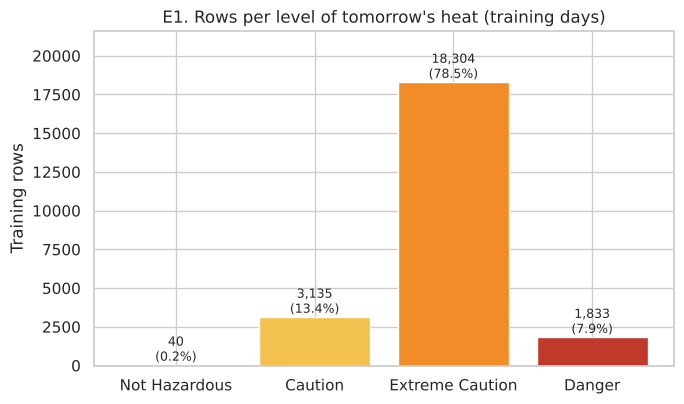

In [5]:
c = tr.Level.value_counts().reindex(LV)
fig, ax = plt.subplots(figsize=(7,4.2))
b = ax.bar(LV, c.values, color=[COL[l] for l in LV])
for r,v in zip(b,c.values): ax.text(r.get_x()+r.get_width()/2, v, f'{v:,}\n({v/c.sum():.1%})', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, c.max()*1.18); ax.set_ylabel('Training rows'); ax.set_title("E1. Rows per level of tomorrow's heat (training days)")
plt.tight_layout(); plt.savefig(FIG / 'E1_class_counts.png', dpi=150); plt.show()

**Finding:** Extreme Caution is 78.5% of rows, Caution 13.4%, Danger 7.9%; Not Hazardous has only 40 rows (0.17%). Always predicting Extreme Caution gives ~78% accuracy.

**Decision:** Use macro-F1 and Danger recall, not accuracy; class weights/stratified training; merge Not Hazardous into Caution (3 classes).

## E2. Histogram of HeatIndex_Max_Today

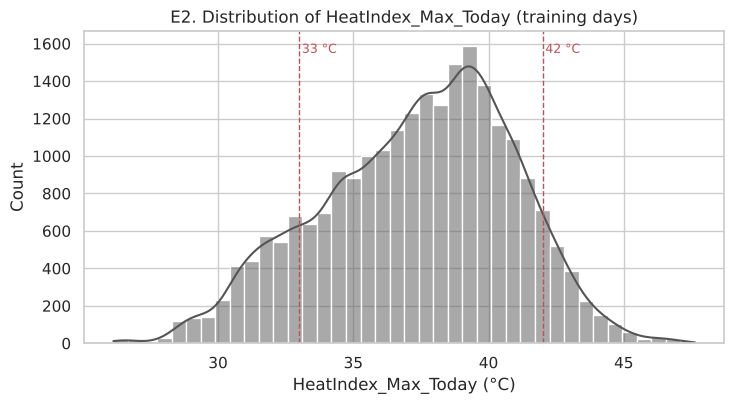

In [6]:
fig, ax = plt.subplots(figsize=(7.5,4.2))
sns.histplot(tr.HeatIndex_Max_Today, bins=40, kde=True, color='#555', ax=ax)
for v in (33, 42): ax.axvline(v, ls='--', c='r', lw=1); ax.text(v+.1, ax.get_ylim()[1]*.93, f'{v} °C', color='r', fontsize=9)
ax.set_xlabel('HeatIndex_Max_Today (°C)'); ax.set_title('E2. Distribution of HeatIndex_Max_Today (training days)')
plt.tight_layout(); plt.savefig(FIG / 'E2_heatindex_hist.png', dpi=150); plt.show()

**Finding:** Roughly bell-shaped with a slight left tail (mean 37.4, median 37.7, skew -0.31, range 26.1–47.6). Most days are 35–40 °C; only a thin tail passes 42 °C.

**Decision:** No transformation for HeatIndex; Danger is a tail event, so keep class weights and watch Danger recall.

## E3. HeatIndex_Max_Today by tomorrow's level

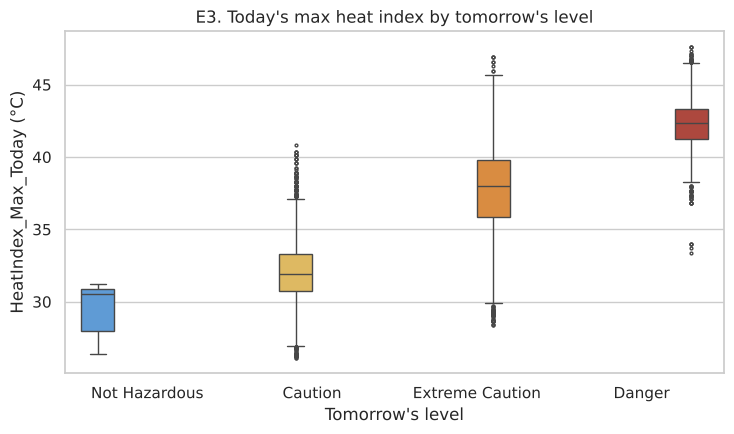

,count,mean,std,min,25%,50%,75%,max
Level,,,,,,,,
Not Hazardous,40.0,29.59,1.51,26.38,28.01,30.55,30.91,31.22
Caution,3135.0,32.15,2.22,26.13,30.76,31.90,33.33,40.83
Extreme Caution,18304.0,37.77,2.73,28.42,35.84,37.99,39.81,46.92
Danger,1833.0,42.26,1.84,33.40,41.22,42.36,43.32,47.63


In [7]:
fig, ax = plt.subplots(figsize=(7.5,4.5))
sns.boxplot(data=tr, x='Level', y='HeatIndex_Max_Today', order=LV, palette=COL, hue='Level', legend=False, ax=ax, fliersize=2)
ax.set_xlabel("Tomorrow's level"); ax.set_ylabel('HeatIndex_Max_Today (°C)'); ax.set_title("E3. Today's max heat index by tomorrow's level")
plt.tight_layout(); plt.savefig(FIG / 'E3_heatindex_by_level.png', dpi=150); plt.show()
display(tr.groupby('Level', observed=True).HeatIndex_Max_Today.describe().round(2))

**Finding:** Medians rise with level: 30.6 / 31.9 / 38.0 / 42.4 °C. Neighbouring levels overlap (Caution up to 40.8, Extreme Caution up to 46.9).

**Decision:** Keep HeatIndex_Max_Today as the main feature; the overlap means other inputs and calendar information are needed.

## E4. Share of each level by month

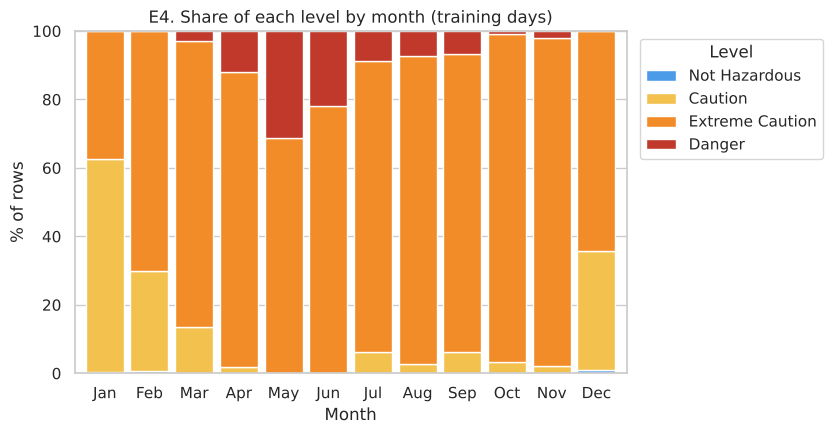

Level,Not Hazardous,Caution,Extreme Caution,Danger
Month,,,,
1,0.5,62.0,37.5,0.0
2,0.6,29.3,70.1,0.0
3,0.0,13.5,83.6,2.9
4,0.0,1.9,86.0,12.1
5,0.0,0.0,68.9,31.1
6,0.0,0.0,78.1,21.9
7,0.0,6.3,84.8,8.9
8,0.0,2.8,89.9,7.3
9,0.0,6.3,86.9,6.8


In [8]:
m = pd.crosstab(tr.Month, tr.Level, normalize='index').reindex(columns=LV)*100
fig, ax = plt.subplots(figsize=(8.5,4.5))
m.plot(kind='bar', stacked=True, color=[COL[l] for l in LV], ax=ax, width=.85)
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)
ax.set_ylabel('% of rows'); ax.set_xlabel('Month'); ax.set_title('E4. Share of each level by month (training days)')
ax.legend(title='Level', bbox_to_anchor=(1.01,1), loc='upper left')
plt.tight_layout(); plt.savefig(FIG / 'E4_level_by_month.png', dpi=150); plt.show()
display(m.round(1))

**Finding:** Danger appears mostly March–September, peaking in May (31.1%) and June (21.9%), then April (12.1%); it is 0% in Jan, Feb, Dec. Caution is highest in Jan (62.0%) and Dec (34.6%).

**Decision:** Add a month feature (cyclical sin/cos or month number).

## E5. Rainfall_Total histogram and storm days

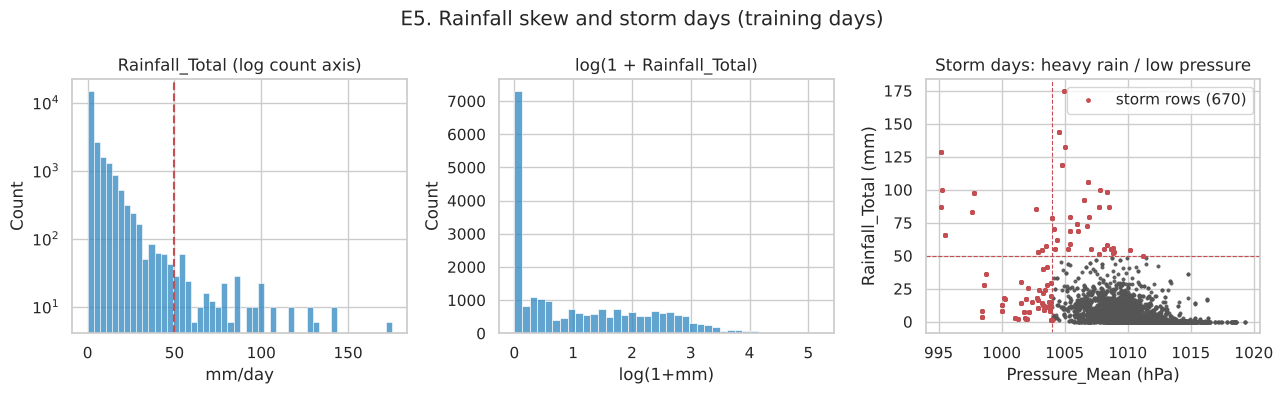

skew raw 5.45 | after log1p 0.73
zero-rain share 0.265 | storm rows 670 (2.9%)
Level
Not Hazardous      0.000
Caution            0.140
Extreme Caution    0.836
Danger             0.024
Name: proportion, dtype: float64


In [9]:
STORM_R, STORM_P = 50, 1004      # heavy rain (mm) or low pressure (hPa)
storm = (tr.Rainfall_Total >= STORM_R) | (tr.Pressure_Mean < STORM_P)
fig, axs = plt.subplots(1, 3, figsize=(13,4))
sns.histplot(tr.Rainfall_Total, bins=50, color='#2E86C1', ax=axs[0]); axs[0].set_yscale('log'); axs[0].axvline(STORM_R, c='r', ls='--')
axs[0].set_title('Rainfall_Total (log count axis)'); axs[0].set_xlabel('mm/day')
sns.histplot(np.log1p(tr.Rainfall_Total), bins=40, color='#2E86C1', ax=axs[1]); axs[1].set_title('log(1 + Rainfall_Total)'); axs[1].set_xlabel('log(1+mm)')
axs[2].scatter(tr.Pressure_Mean, tr.Rainfall_Total, s=3, alpha=.25, c='#555')
s = tr[storm]; axs[2].scatter(s.Pressure_Mean, s.Rainfall_Total, s=6, c='r', label=f'storm rows ({len(s):,})')
axs[2].axhline(STORM_R, c='r', ls='--', lw=.8); axs[2].axvline(STORM_P, c='r', ls='--', lw=.8)
axs[2].set_xlabel('Pressure_Mean (hPa)'); axs[2].set_ylabel('Rainfall_Total (mm)'); axs[2].legend(); axs[2].set_title('Storm days: heavy rain / low pressure')
fig.suptitle('E5. Rainfall skew and storm days (training days)'); plt.tight_layout(); plt.savefig(FIG / 'E5_rainfall_storms.png', dpi=150); plt.show()
print('skew raw', round(tr.Rainfall_Total.skew(),2), '| after log1p', round(np.log1p(tr.Rainfall_Total).skew(),2))
print('zero-rain share', round((tr.Rainfall_Total==0).mean(),3), '| storm rows', storm.sum(), f'({storm.mean():.1%})')
print(tr[storm].Level.value_counts(normalize=True).reindex(LV).round(3))

**Finding:** Very skewed (skew 5.45; 26.5% exactly 0 mm; max 175 mm); log(1+x) brings skew to 0.73. Storm days are 670 rows (2.9%) and 83.6% are followed by Extreme Caution. Heavy rain and low pressure go together.

**Decision:** Keep storm rows (real, not errors). Log-transform Rainfall_Total for Logistic Regression (trees don't need it). Optional storm flag.

## E6. Correlation (Spearman)

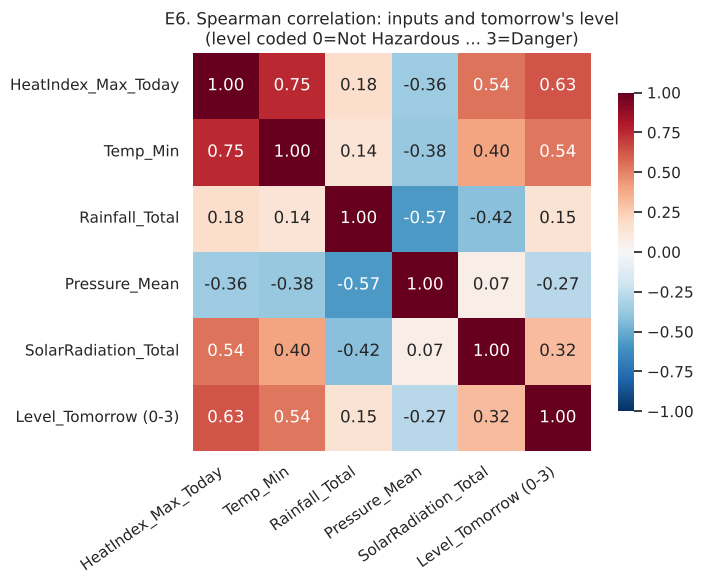

In [10]:
cm = tr[X+['LevelCode']].rename(columns={'LevelCode':'Level_Tomorrow (0-3)'}).corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5,6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={'shrink':.8})
ax.set_title("E6. Spearman correlation: inputs and tomorrow's level\n(level coded 0=Not Hazardous ... 3=Danger)"); plt.xticks(rotation=35, ha='right')
plt.tight_layout(); plt.savefig(FIG / 'E6_correlation.png', dpi=150); plt.show()

**Finding:** With tomorrow's level: HeatIndex 0.63, Temp_Min 0.54, Solar 0.32, Pressure -0.27, Rainfall 0.15. Among inputs: HeatIndex–Temp_Min 0.75, HeatIndex–Solar 0.54, Rainfall–Pressure -0.57, Rainfall–Solar -0.42.

**Decision:** Keep all 5 inputs (no pair above 0.8); scale for Logistic Regression and use regularisation; trees are unaffected.

## E7. Share of Danger rows by city and by year

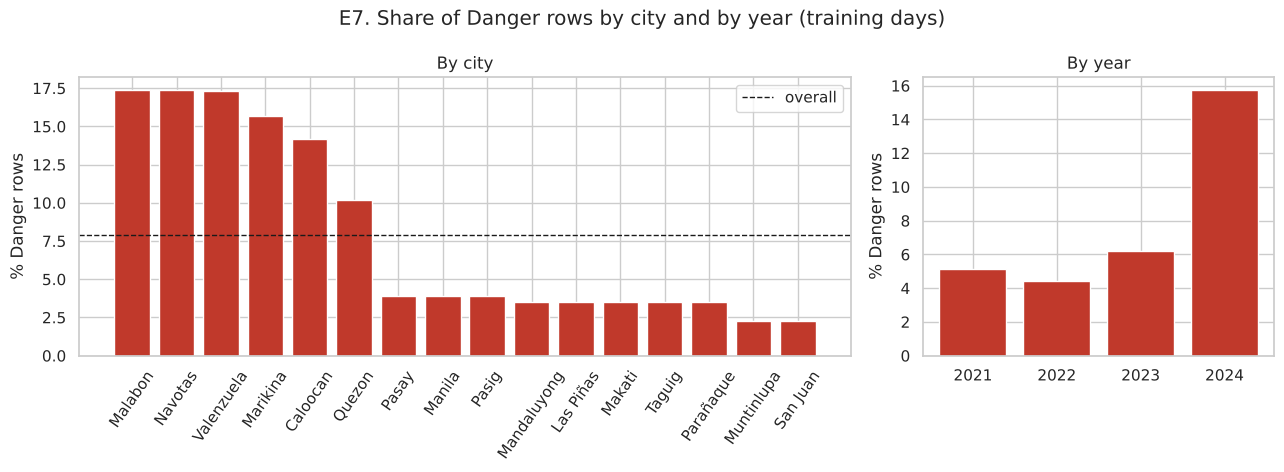

City
Malabon        17.4
Navotas        17.4
Valenzuela     17.3
Marikina       15.6
Caloocan       14.2
Quezon         10.2
Pasay           3.9
Manila          3.9
Pasig           3.9
Mandaluyong     3.5
Las Piñas       3.5
Makati          3.5
Taguig          3.5
Parañaque       3.5
Muntinlupa      2.3
San Juan        2.3
Name: Danger, dtype: float64
Year
2021     5.2
2022     4.4
2023     6.2
2024    15.7
Name: Danger, dtype: float64


In [11]:
tr['Danger'] = (tr.Level == 'Danger')
bc = tr.groupby('City').Danger.mean().sort_values(ascending=False)*100
by = tr.groupby('Year').Danger.mean()*100
fig, axs = plt.subplots(1, 2, figsize=(13,4.8), gridspec_kw={'width_ratios':[2.2,1]})
axs[0].bar(bc.index, bc.values, color='#C0392B'); axs[0].axhline(tr.Danger.mean()*100, ls='--', c='k', lw=1, label='overall')
axs[0].tick_params(axis='x', rotation=55); axs[0].set_ylabel('% Danger rows'); axs[0].set_title('By city'); axs[0].legend()
axs[1].bar(by.index.astype(str), by.values, color='#C0392B'); axs[1].set_title('By year'); axs[1].set_ylabel('% Danger rows')
fig.suptitle('E7. Share of Danger rows by city and by year (training days)'); plt.tight_layout(); plt.savefig(FIG / 'E7_danger_city_year.png', dpi=150); plt.show()
print(bc.round(1)); print(by.round(1))

**Finding:** Danger is concentrated: Malabon/Navotas/Valenzuela ~17%, Marikina 15.6%, Caloocan 14.2%, Quezon 10.2%, vs 2.3–3.9% elsewhere. By year: 5.2% (2021), 4.4% (2022), 6.2% (2023), **15.7% (2024)**.

**Decision:** Include City as a feature. Cities share weather stations and years differ a lot, so use time-aware / date-grouped CV, not a random row split. 2024's Danger rate is unrepresentative of 2025 (5.94% in test).

## Findings summary (links to Section 4)
1. Imbalanced target, 4 levels, one tiny (E1) → merge Not Hazardous into Caution; macro-F1 + Danger recall; class weights.
2. Clean data: no missing values or duplicates → no imputation/deduplication.
3. HeatIndex_Max_Today and Temp_Min are the strongest predictors (E2, E3, E6); neighbouring levels overlap.
4. Strong seasonality (E4) → month features.
5. Rainfall skewed, storm outliers real (E5) → keep rows, log-transform for Logistic Regression.
6. Cities and years differ; cities share stations (E7) → City feature, date-grouped / time-aware CV.

## Notes added when this notebook was merged into the repository
* The notebook now loads the data and makes the train/test split with `src/common.py`, like the model notebooks. Marc's first version cut at 80% of the dates, which kept the day 2024-12-28 in the training days; the shared split skips that day. With the shared split, four numbers above changed slightly and were updated: Caution 13.4% of training rows (E1), Caution 34.6% of December rows (E4), Pressure −0.27 with tomorrow's level (E6) and 5.94% Danger rows in the test days (E7).
* Figures are saved in `results/eda/`.
* Three of the decisions above were changed later by the group (Group Workspace Sections 3 and 4): all five PAGASA levels were kept as labels and the models are judged on the three core levels, instead of merging Not Hazardous into Caution; no month feature was added, so that all three models use the same five inputs; and log(1 + rainfall) was tested for Logistic Regression but not kept, because it changed the scores by less than 0.01.